In [1]:
import pandas as pd
import yfinance as yf
import requests
from io import StringIO

url = "https://www.niftyindices.com/IndexConstituent/ind_nifty100list.csv"

headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "text/csv,application/csv,text/plain,*/*",
    "Referer": "https://www.niftyindices.com/"
}

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

response.raise_for_status()

nifty100 = pd.read_csv(StringIO(response.text))

print(nifty100[["Company Name", "Symbol"]])
print("Number of companies:", len(nifty100))

tickers = [symbol + ".NS" for symbol in nifty100["Symbol"]]

print(tickers)

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-10-06",
    group_by="ticker",
    auto_adjust=True,
    threads=True
)

print(data.head())

                                  Company Name      Symbol
0                               ABB India Ltd.         ABB
1                  Adani Energy Solutions Ltd.  ADANIENSOL
2                       Adani Enterprises Ltd.    ADANIENT
3                      Adani Green Energy Ltd.  ADANIGREEN
4   Adani Ports and Special Economic Zone Ltd.  ADANIPORTS
..                                         ...         ...
95                Vedanta Aluminium Metal Ltd.        VAML
96                                Vedanta Ltd.        VEDL
97                          Vodafone Idea Ltd.        IDEA
98                                  Wipro Ltd.       WIPRO
99                     Zydus Lifesciences Ltd.   ZYDUSLIFE

[100 rows x 2 columns]
Number of companies: 100
['ABB.NS', 'ADANIENSOL.NS', 'ADANIENT.NS', 'ADANIGREEN.NS', 'ADANIPORTS.NS', 'ADANIPOWER.NS', 'AMBUJACEM.NS', 'APOLLOHOSP.NS', 'ASIANPAINT.NS', 'DMART.NS', 'AXISBANK.NS', 'BSE.NS', 'BAJAJ-AUTO.NS', 'BAJFINANCE.NS', 'BAJAJFINSV.NS', 'BAJAJHLDNG

[*********************100%***********************]  100 of 100 completed

Ticker     JIOFIN.NS                       AMBUJACEM.NS              \
Price           Open High Low Close Volume         Open        High   
Date                                                                  
2020-01-01       NaN  NaN NaN   NaN    NaN   175.384247  175.873404   
2020-01-02       NaN  NaN NaN   NaN    NaN   175.517679  183.566490   
2020-01-03       NaN  NaN NaN   NaN    NaN   182.276891  183.032863   
2020-01-06       NaN  NaN NaN   NaN    NaN   180.409209  180.409209   
2020-01-07       NaN  NaN NaN   NaN    NaN   176.184708  180.142413   

Ticker                                       ...      M&M.NS              \
Price              Low       Close   Volume  ...        Open        High   
Date                                         ...                           
2020-01-01  174.139131  175.206375  1459556  ...  500.952526  505.746757   
2020-01-02  175.384265  182.632660  8633553  ...  504.806630  508.566828   
2020-01-03  179.875588  180.898361  2007973  ...  5

In [2]:
import pandas

fields = ["Open","High","Low","Close","Volume"]
panels = {f.lower(): data.xs(f, axis=1, level="Price") for f in fields}

close = panels["close"]
close

Ticker,JIOFIN.NS,AMBUJACEM.NS,AXISBANK.NS,TECHM.NS,POLYCAB.NS,HDFCBANK.NS,HCLTECH.NS,CANBK.NS,NESTLEIND.NS,CGPOWER.NS,...,DIVISLAB.NS,BSE.NS,IDEA.NS,BANKBARODA.NS,ONGC.NS,JINDALSTEL.NS,ASIANPAINT.NS,RELIANCE.NS,M&M.NS,BHARTIARTL.NS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,NaN,175.206375,745.012329,587.353882,955.442139,595.677124,446.139343,37.519474,687.276978,10.816883,...,1744.093262,50.409786,6.10,87.505669,85.009651,163.787796,1690.746338,672.216187,504.430664,427.930878
2020-01-02,NaN,182.632660,753.221741,590.398193,939.243958,599.474121,447.387512,38.738235,684.965759,11.162628,...,1750.853760,52.588821,6.10,89.695457,85.409843,170.530258,1688.342285,683.660278,507.485748,429.724487
2020-01-03,NaN,180.898361,739.290710,597.372925,944.242859,590.925171,456.357849,37.519474,678.652832,11.705943,...,1759.387939,51.728279,6.10,86.603989,85.676636,168.906174,1651.334839,684.484070,500.811493,429.630066
2020-01-06,NaN,175.117432,719.687622,593.750610,923.430603,578.136780,453.978821,35.115791,670.424072,11.952904,...,1762.791870,49.966930,6.00,82.267349,84.209236,164.279938,1609.613037,668.609314,493.056091,424.485168
2020-01-07,NaN,176.985138,722.175354,598.914368,922.613464,587.291382,455.733826,35.217346,664.569397,11.804727,...,1768.113892,49.805893,6.00,82.567924,83.875740,164.722900,1625.877319,678.895630,495.077240,420.189789
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-29,217.559998,365.750000,1212.099976,1510.500000,8102.500000,722.700012,1222.000000,119.510002,1345.699951,858.049988,...,9431.000000,3200.000000,13.56,227.679993,230.000000,1130.000000,2415.000000,1182.000000,2947.800049,1771.199951
2026-09-30,216.880005,374.000000,1226.000000,1524.000000,8026.000000,708.700012,1230.000000,119.440002,1310.000000,854.200012,...,9291.500000,3092.000000,12.95,230.550003,225.800003,1134.900024,2402.600098,1187.000000,2950.000000,1757.000000
2026-10-01,212.500000,362.250000,1217.099976,1533.000000,7990.000000,721.200012,1243.099976,118.360001,1307.699951,879.000000,...,9249.000000,3046.000000,12.64,230.820007,222.369995,1100.500000,2407.000000,1167.699951,2860.000000,1741.099976


In [3]:
complete = close.dropna(axis=1, how="any").dropna(axis=0, how="any")

print("tickers:", close.shape[1], "->", complete.shape[1])
print("dates:  ", close.shape[0], "->", complete.shape[0])
print("dropped tickers:", sorted(set(close.columns) - set(complete.columns)))

panels = {n: p.loc[complete.index, complete.columns] for n, p in panels.items()}
open_, high, low, close, volume = (
    panels[n] for n in ["open", "high", "low", "close", "volume"]
)

assert not any(p.isna().any().any() for p in panels.values()), "NaNs remain"
open_


tickers: 100 -> 80
dates:   1679 -> 1679
dropped tickers: ['BAJAJHLDNG.NS', 'BOSCHLTD.NS', 'DIVISLAB.NS', 'ENRIN.NS', 'ETERNAL.NS', 'GRASIM.NS', 'HYUNDAI.NS', 'INDIGO.NS', 'IRFC.NS', 'JIOFIN.NS', 'MAXHEALTH.NS', 'MAZDOCK.NS', 'NESTLEIND.NS', 'POWERINDIA.NS', 'SIEMENS.NS', 'SOLARINDS.NS', 'TATACAP.NS', 'TMCV.NS', 'VAML.NS', 'ZYDUSLIFE.NS']


Ticker,AMBUJACEM.NS,AXISBANK.NS,TECHM.NS,POLYCAB.NS,HDFCBANK.NS,HCLTECH.NS,CANBK.NS,CGPOWER.NS,MOTHERSON.NS,PIDILITIND.NS,...,BAJFINANCE.NS,BSE.NS,IDEA.NS,BANKBARODA.NS,ONGC.NS,JINDALSTEL.NS,ASIANPAINT.NS,RELIANCE.NS,M&M.NS,BHARTIARTL.NS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,175.384247,751.181803,590.359648,949.914629,594.512418,444.150271,37.595644,10.866275,37.586168,669.722872,...,411.637015,50.374557,6.20,87.806227,85.876758,165.165827,1687.917741,675.956671,500.952526,430.526963
2020-01-02,175.517679,746.305960,587.353901,955.538105,595.863533,446.607480,37.646421,10.866275,37.330479,677.901015,...,411.850680,50.706695,6.00,87.677418,85.143041,167.232842,1688.672265,673.284921,504.806630,428.686036
2020-01-03,182.276891,749.440484,590.359534,940.157308,597.354313,447.738502,38.560506,11.360198,38.302097,673.317367,...,409.907963,52.629081,6.10,89.266083,87.377497,170.628702,1678.112245,682.636062,506.639813,430.196502
2020-01-06,180.409209,735.807841,597.180207,934.389516,587.011863,456.318918,37.333273,11.705943,37.726797,669.385095,...,404.468464,51.733312,6.05,85.831117,86.510397,166.593053,1638.653229,676.847260,498.132383,428.497301
2020-01-07,176.184708,724.414272,593.442385,932.466851,586.499404,453.978753,36.122959,12.249256,36.563420,670.711901,...,393.880741,50.726826,6.00,83.813096,83.775688,166.346992,1613.242898,676.401934,497.192352,426.703645
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-29,373.500000,1202.000000,1542.300049,8195.000000,713.700012,1252.599976,120.000000,865.000000,162.080002,1493.000000,...,977.500000,3100.000000,13.60,227.500000,230.000000,1137.500000,2417.500000,1193.800049,2986.000000,1764.000000
2026-09-30,369.000000,1201.099976,1524.599976,8102.500000,711.500000,1229.000000,119.699997,866.450012,160.350006,1481.000000,...,981.500000,3138.899902,13.60,230.399994,230.210007,1130.000000,2410.000000,1182.000000,2925.000000,1775.199951
2026-10-01,371.500000,1219.099976,1540.000000,8030.000000,708.400024,1230.000000,119.449997,861.000000,161.350006,1468.099976,...,953.900024,3089.899902,12.95,230.000000,224.750000,1130.500000,2391.000000,1180.099976,2926.000000,1745.000000


In [4]:
returns = close.pct_change(fill_method=None)
returns

Ticker,AMBUJACEM.NS,AXISBANK.NS,TECHM.NS,POLYCAB.NS,HDFCBANK.NS,HCLTECH.NS,CANBK.NS,CGPOWER.NS,MOTHERSON.NS,PIDILITIND.NS,...,BAJFINANCE.NS,BSE.NS,IDEA.NS,BANKBARODA.NS,ONGC.NS,JINDALSTEL.NS,ASIANPAINT.NS,RELIANCE.NS,M&M.NS,BHARTIARTL.NS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,0.042386,0.011019,0.005183,-0.016954,0.006374,0.002798,0.032483,0.031963,0.028140,-0.004483,...,0.003486,0.043226,0.000000,0.025025,0.004708,0.041166,-0.001422,0.017024,0.006056,0.004191
2020-01-03,-0.009496,-0.018495,0.011814,0.005322,-0.014261,0.020050,-0.031461,0.048673,-0.010681,-0.001001,...,-0.012388,-0.016364,0.000000,-0.034466,0.003124,-0.009524,-0.021919,0.001205,-0.013152,-0.000220
2020-01-06,-0.031957,-0.026516,-0.006064,-0.022041,-0.021641,-0.005213,-0.064065,0.021097,-0.048246,-0.007119,...,-0.046918,-0.034050,-0.016393,-0.050074,-0.017127,-0.027389,-0.025266,-0.023192,-0.015486,-0.011975
2020-01-07,0.010665,0.003457,0.008697,-0.000885,0.015835,0.003866,0.002892,-0.012397,0.026232,0.008647,...,0.002740,-0.003223,0.000000,0.003654,-0.003960,0.002696,0.010104,0.015385,0.004099,-0.010119
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-29,-0.022973,0.001818,-0.020555,-0.010805,0.005076,-0.024429,-0.009449,-0.008035,-0.023465,-0.027944,...,-0.011371,0.033091,0.006682,0.000791,0.000000,-0.008424,-0.002066,-0.013026,-0.015760,-0.000113
2026-09-30,0.022556,0.011468,0.008937,-0.009442,-0.019372,0.006547,-0.000586,-0.004487,0.029642,0.002806,...,-0.014787,-0.033750,-0.044985,0.012605,-0.018261,0.004336,-0.005135,0.004230,0.000746,-0.008017
2026-10-01,-0.031417,-0.007259,0.005906,-0.004485,0.017638,0.010650,-0.009042,0.029033,-0.038160,-0.000751,...,-0.011570,-0.014877,-0.023938,0.001171,-0.015190,-0.030311,0.001831,-0.016260,-0.030508,-0.009050


In [5]:
def rank(x):
    return x.rank(axis=1, pct=True)


def scale(x, a=1.0):
    return x.mul(a).div(x.abs().sum(axis=1), axis=0)


def zscore(x):
    return x.sub(x.mean(axis=1), axis=0).div(x.std(axis=1), axis=0)


def delay(x, d):          return x.shift(d)
def delta(x, d):          return x - x.shift(d)
def ts_sum(x, d):         return x.rolling(d).sum()
def ts_mean(x, d):        return x.rolling(d).mean()
def ts_std(x, d):         return x.rolling(d).std()
def ts_min(x, d):         return x.rolling(d).min()
def ts_max(x, d):         return x.rolling(d).max()
def ts_rank(x, d):        return x.rolling(d).rank(pct=True)        
def ts_argmax(x, d):      return x.rolling(d).apply(np.argmax, raw=True) + 1


def correlation(x, y, d):
    return x.rolling(d).corr(y).replace([np.inf, -np.inf], np.nan)


def covariance(x, y, d):
    return x.rolling(d).cov(y)


def decay_linear(x, d):
    w = np.arange(1, d + 1, dtype=float)
    w /= w.sum()                                  
    return x.rolling(d).apply(lambda a: np.dot(a, w), raw=True)


def sign(x):              return np.sign(x)
def signed_power(x, a):   return np.sign(x) * x.abs() ** a


In [6]:
import numpy as np

alphas = {
    "rev5":      -delta(close, 5) / delay(close, 5),
    "mom12_1":   delay(close, 21) / delay(close, 252) - 1,
    "lowvol":    -ts_std(returns, 20),
    "volshock":  -rank(volume / ts_mean(volume, 20)) * rank(returns),
    "near_high": close / ts_max(close, 250),
}

alphas = {k: v.where(close.notna()) for k, v in alphas.items()}
alphas


{'rev5': Ticker      AMBUJACEM.NS  AXISBANK.NS  TECHM.NS  POLYCAB.NS  HDFCBANK.NS  \
 Date                                                                       
 2020-01-01           NaN          NaN       NaN         NaN          NaN   
 2020-01-02           NaN          NaN       NaN         NaN          NaN   
 2020-01-03           NaN          NaN       NaN         NaN          NaN   
 2020-01-06           NaN          NaN       NaN         NaN          NaN   
 2020-01-07           NaN          NaN       NaN         NaN          NaN   
 ...                  ...          ...       ...         ...          ...   
 2026-09-29      0.054665     0.024624  0.026489    0.029641     0.021527   
 2026-09-30      0.047740     0.013835  0.021195    0.046454     0.038725   
 2026-10-01      0.056886    -0.025790  0.006481    0.045001     0.010564   
 2026-10-02      0.056149     0.004336  0.009690    0.049771     0.019576   
 2026-10-05      0.020970    -0.010166  0.004085    0.013551     0.0

In [7]:
def clipping(x,q = 0.01):
    lo,hi = x.quantile(q,axis = 1),x.quantile(1-q,axis=1)
    return x.clip(lower = lo,upper = hi,axis = 0)

def sub_mean(x):
    return x.sub(x.mean(axis = 1),axis = 0)


def process(raw,decay = 0):
    a  = rank(clipping(raw)) - 0.5
    a  = sub_mean(a)
    if decay:
        a = decay_linear(a.fillna(0),decay).where(raw.notna())

    return scale(a)

processed = {k:process(v) for k,v in alphas.items()}

w = processed['rev5']
print(w.sum(axis = 1).abs().max())
print(w.abs().sum(axis=1).describe())

1.3877787807814457e-16
count    1679.000000
mean        0.997022
std         0.054506
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
dtype: float64


gross: {'ann_return': 0.02, 'ann_vol': 0.069, 'sharpe': 0.295, 'max_drawdown': -0.128}
net:   {'ann_return': -0.198, 'ann_vol': 0.069, 'sharpe': -2.881, 'max_drawdown': -1.353}
turnover/day: 0.579


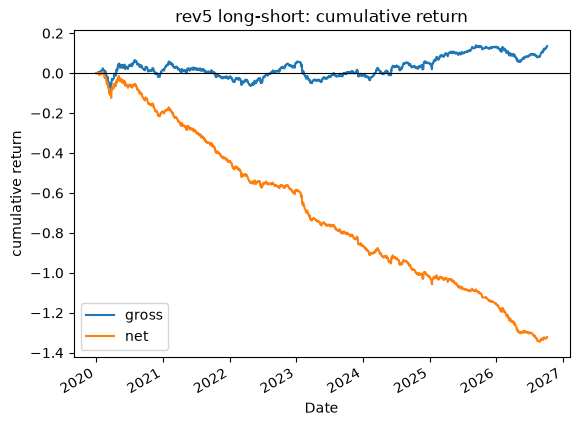

In [8]:
import matplotlib.pyplot as plt

BPS_COST = 15 # transiction cost

def backtest(w, returns, cost_bps=BPS_COST, delay=1):
    pos      = w.shift(delay + 1).fillna(0)
    gross    = (pos * returns.fillna(0)).sum(axis=1)
    turnover = (pos - pos.shift(1)).abs().sum(axis=1)
    return pd.DataFrame({"gross": gross,
                         "net": gross - turnover * cost_bps / 1e4,
                         "turnover": turnover})

def stats(pnl):
    ann_ret, ann_vol = pnl.mean() * 252, pnl.std() * np.sqrt(252)
    cum = pnl.cumsum()
    return pd.Series({"ann_return": ann_ret, "ann_vol": ann_vol,
                      "sharpe": ann_ret / ann_vol,
                      "max_drawdown": (cum - cum.cummax()).min()})

bt = backtest(processed["rev5"], returns)
print("gross:", stats(bt["gross"]).round(3).to_dict())
print("net:  ", stats(bt["net"]).round(3).to_dict())
print("turnover/day:", bt["turnover"].mean().round(3))

bt[["gross", "net"]].cumsum().plot(title="rev5 long-short: cumulative return")
plt.axhline(0, lw=0.8, color="black")
plt.ylabel("cumulative return")
plt.show()


In [ ]:
BOOK = 2.0e7          
CAPITAL = BOOK / 2    

def evaluate(bt, book=BOOK, col="net"):
    capital = book / 2
    r = bt[col]                                   
    rows = {}

    for year, idx in list(r.groupby(r.index.year).groups.items()) + [("all", r.index)]:
        pnl_r  = r.loc[idx]                       
        turn   = bt["turnover"].loc[idx]
        n      = len(pnl_r)

        pnl_cur = pnl_r * book                    
        ret     = pnl_r * book / capital          
        cum     = ret.cumsum()
        traded  = (turn * book).sum()

        rows[year] = {
            "book_size":   book,
            "pnl":         pnl_cur.sum(),
            "ann_return":  ret.mean() * 252,
            "info_ratio":  ret.mean() / ret.std() * np.sqrt(252),
            "max_dd":      -(cum - cum.cummax()).min(),
            "pct_days":    (pnl_r > 0).mean(),
            "turnover":    turn.mean(),
            "profit_per_$": pnl_cur.sum() / traded * 100,   
        }

    out = pd.DataFrame(rows).T
    return out


bt  = backtest(processed["rev5"], returns)
tbl = evaluate(bt)

fmt = tbl.copy()
for c in ["ann_return", "max_dd", "pct_days", "turnover"]:
    fmt[c] = (tbl[c] * 100).round(2).astype(str) + "%"
fmt["book_size"]    = tbl["book_size"].map("{:.1E}".format)
fmt["pnl"]          = tbl["pnl"].map("{:.2E}".format)
fmt["info_ratio"]   = tbl["info_ratio"].round(2)
fmt["profit_per_$"] = tbl["profit_per_$"].round(2).astype(str) + "¢"
print(fmt.to_string())


     book_size        pnl ann_return  info_ratio   max_dd pct_days turnover profit_per_$
2020   2.0E+07  -3.84E+06    -38.59%       -2.00   44.81%   39.84%   55.68%       -0.14¢
2021   2.0E+07  -5.06E+06     -51.4%       -4.07   54.93%   40.32%    57.1%       -0.18¢
2022   2.0E+07  -2.83E+06    -28.73%       -2.13   33.37%   41.53%   58.09%        -0.1¢
2023   2.0E+07  -5.56E+06    -57.23%       -4.41    56.5%   37.14%   58.67%       -0.19¢
2024   2.0E+07  -3.09E+06    -31.69%       -2.35   33.12%   42.68%   58.62%       -0.11¢
2025   2.0E+07  -2.73E+06    -27.61%       -2.61   28.53%   38.55%   58.17%       -0.09¢
2026   2.0E+07  -3.33E+06    -43.66%       -3.71   37.46%   39.06%   59.06%       -0.15¢
all    2.0E+07  -2.64E+07    -39.69%       -2.88  270.64%    39.9%   57.87%       -0.14¢
